<center><h1>Chen_Yanxiong_HW5</h1></center>
<br>
<br>

Name: Yanxiong Chen
<br>
Github Username: DevinChen02
<br>
USC ID: 2129850673

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from contextlib import redirect_stdout
from io import StringIO
from sklearn.impute import SimpleImputer
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import RidgeCV
import numpy as np
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import PCA
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
df = pd.read_csv(
    "../data/diagnosis.data",
    sep="\t",
    header=None,
    encoding="utf-16",
    decimal=","
)
df.head()

,0,1,2,3,4,5,6,7
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### (b) Build a decision tree

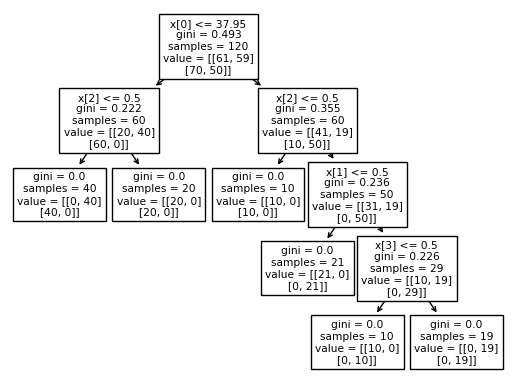

In [3]:
X = df.iloc[:, :6].replace({"yes": 1, "no": 0})
y = df.iloc[:, 6:]

model = DecisionTreeClassifier()
model.fit(X, y)

plot_tree(model)
plt.show()

### (c) Convert the decision rules

In [4]:
# reference: KDnuggets article “Simplifying Decision Tree Interpretability with Python & Scikit-learn”
def print_rules(node, conditions):
    tree = model.tree_

    if tree.children_left[node] == -1:
        predictions = [
            model.classes_[i][tree.value[node, i].argmax()]
            for i in range(y.shape[1])
        ]
        print("IF", " AND ".join(conditions), "THEN", predictions)
    else:
        feature = f"X[{tree.feature[node]}]"
        threshold = tree.threshold[node]

        print_rules(tree.children_left[node],
                    conditions + [f"{feature} <= {threshold}"])
        print_rules(tree.children_right[node],
                    conditions + [f"{feature} > {threshold}"])

print_rules(0, [])

IF X[0] <= 37.95000076293945 AND X[2] <= 0.5 THEN ['yes', 'no']
IF X[0] <= 37.95000076293945 AND X[2] > 0.5 THEN ['no', 'no']
IF X[0] > 37.95000076293945 AND X[2] <= 0.5 THEN ['no', 'no']
IF X[0] > 37.95000076293945 AND X[2] > 0.5 AND X[1] <= 0.5 THEN ['no', 'yes']
IF X[0] > 37.95000076293945 AND X[2] > 0.5 AND X[1] > 0.5 AND X[3] <= 0.5 THEN ['no', 'yes']
IF X[0] > 37.95000076293945 AND X[2] > 0.5 AND X[1] > 0.5 AND X[3] > 0.5 THEN ['yes', 'yes']


### (d) Find a minimal decision tree and a set of decision rules with high interpretability

Selected alpha: 0.0
Number of leaves: 6


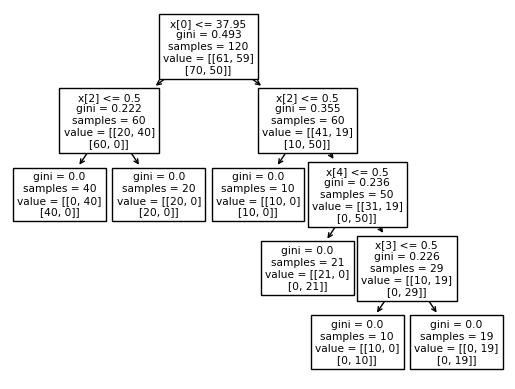

Predictions: [bladder inflammation, nephritis]
IF temperature <= 37.95000076293945 AND lumbar pain = no THEN [1, 0]
IF temperature <= 37.95000076293945 AND lumbar pain = yes THEN [0, 0]
IF temperature > 37.95000076293945 AND lumbar pain = no THEN [0, 0]
IF temperature > 37.95000076293945 AND lumbar pain = yes AND micturition pain = no THEN [0, 1]
IF temperature > 37.95000076293945 AND lumbar pain = yes AND micturition pain = yes AND urine pushing = no THEN [0, 1]
IF temperature > 37.95000076293945 AND lumbar pain = yes AND micturition pain = yes AND urine pushing = yes THEN [1, 1]



In [5]:
y = y.replace({"yes": 1, "no": 0}).astype(int)

alphas = model.cost_complexity_pruning_path(X, y).ccp_alphas
search = GridSearchCV(
    DecisionTreeClassifier(),
    {"ccp_alpha": alphas[::-1]}
)
search.fit(X, y)

model = search.best_estimator_
print("Selected alpha:", search.best_params_["ccp_alpha"])
print("Number of leaves:", model.get_n_leaves())
plot_tree(model)
plt.show()

output = StringIO()
with redirect_stdout(output):
    print_rules(0, [])
rules = output.getvalue()
names = ["temperature", "nausea", "lumbar pain",
         "urine pushing", "micturition pain", "burning of urethra"]
for i, name in enumerate(names):
    rules = rules.replace(f"X[{i}]", name)

rules = rules.replace(" <= 0.5", " = no").replace(" > 0.5", " = yes")
rules = rules.replace("np.int64(0)", "'no'").replace("np.int64(1)", "'yes'")
print("Predictions: [bladder inflammation, nephritis]")
print(rules)

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
data = pd.read_csv("../data/communities.data", header=None)
train = data.iloc[:1495]
test = data.iloc[1495:]
train.shape, test.shape

((1495, 128), (499, 128))

### (b) Missing values

In [7]:
X_train = train.iloc[:, 5:-1].replace("?", float("nan")).astype(float)
X_test = test.iloc[:, 5:-1].replace("?", float("nan")).astype(float)
y_train = train.iloc[:, -1]
y_test = test.iloc[:, -1]

imputer = SimpleImputer()
X_train[:] = imputer.fit_transform(X_train)
X_test[:] = imputer.transform(X_test)

### (c) Plot a correlation matrix

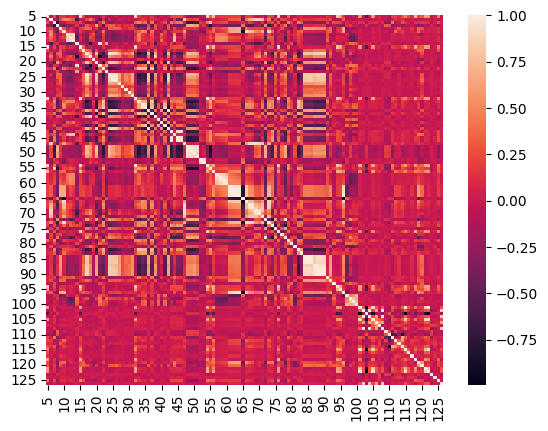

In [8]:
sns.heatmap(X_train.corr())
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [9]:
CV = X_train.std() / X_train.mean()
CV

5      2.241105
6      0.355800
7      1.428885
8      0.330213
9      1.359100
         ...   
122    0.743487
123    0.115739
124    0.362989
125    2.552946
126    0.326026
Length: 122, dtype: float64

### (e) Scatter plots and box plots for highest CV features

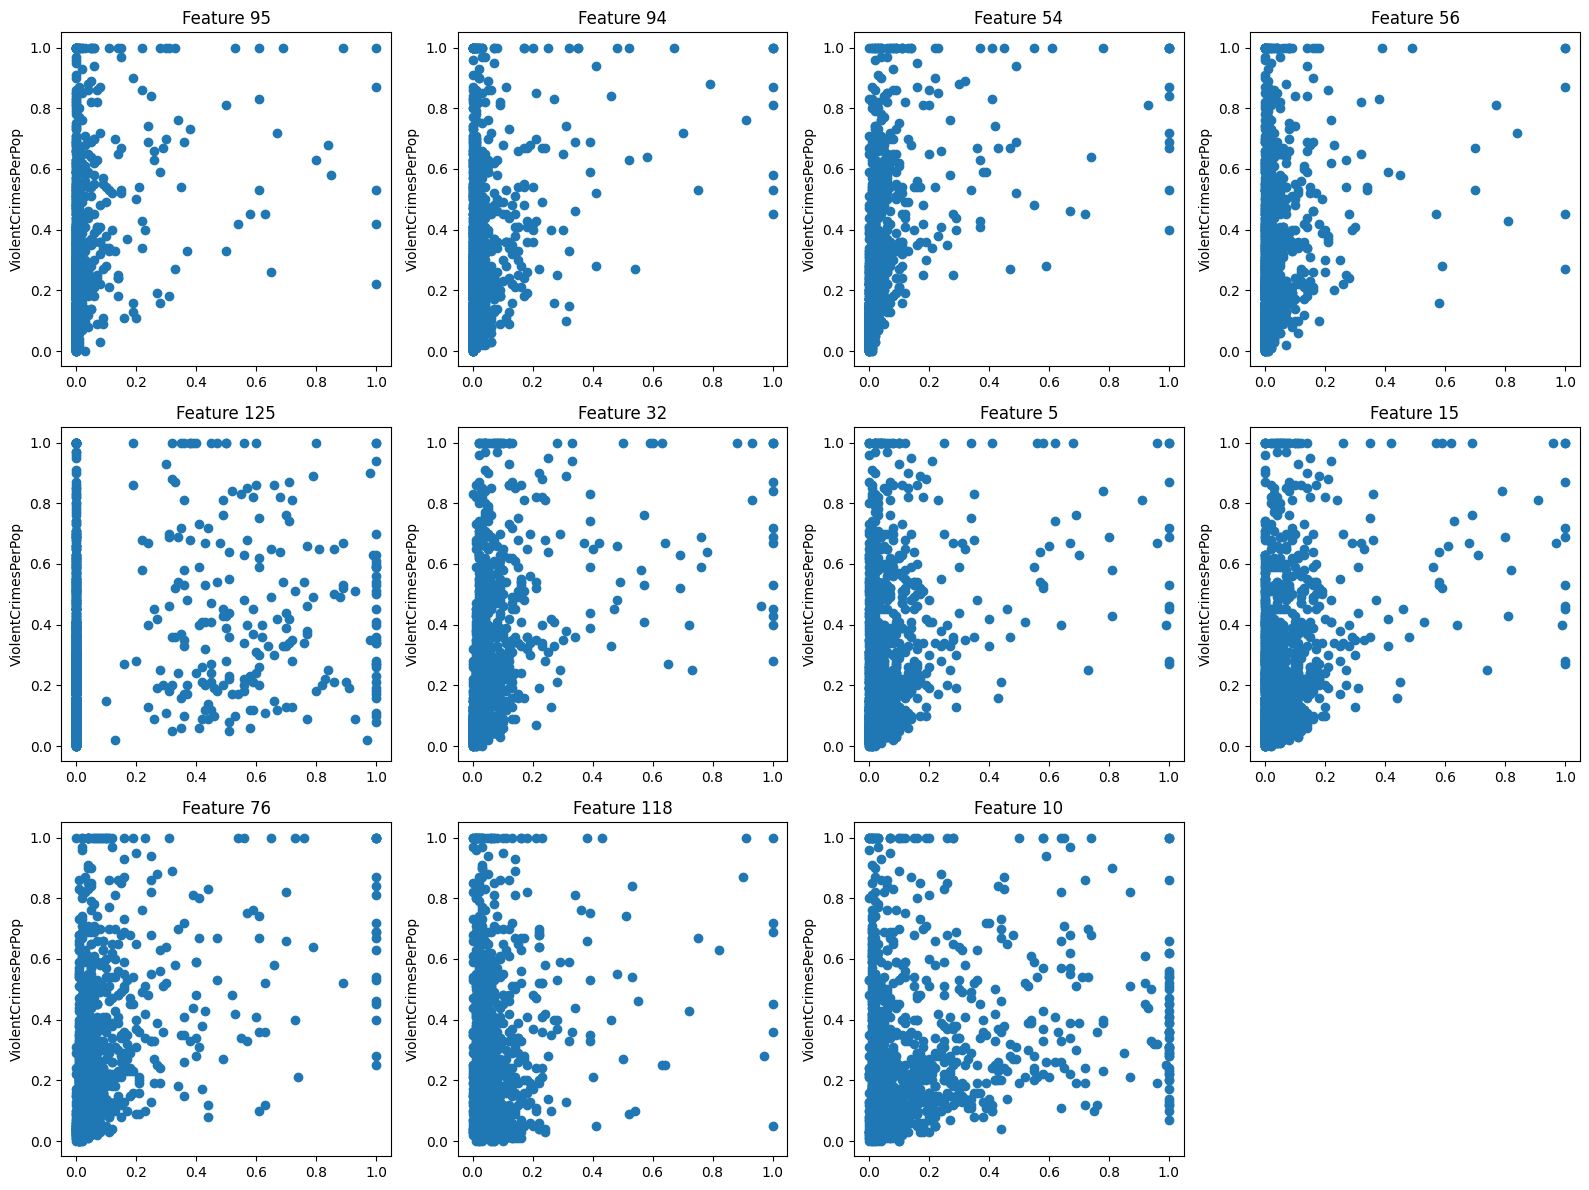

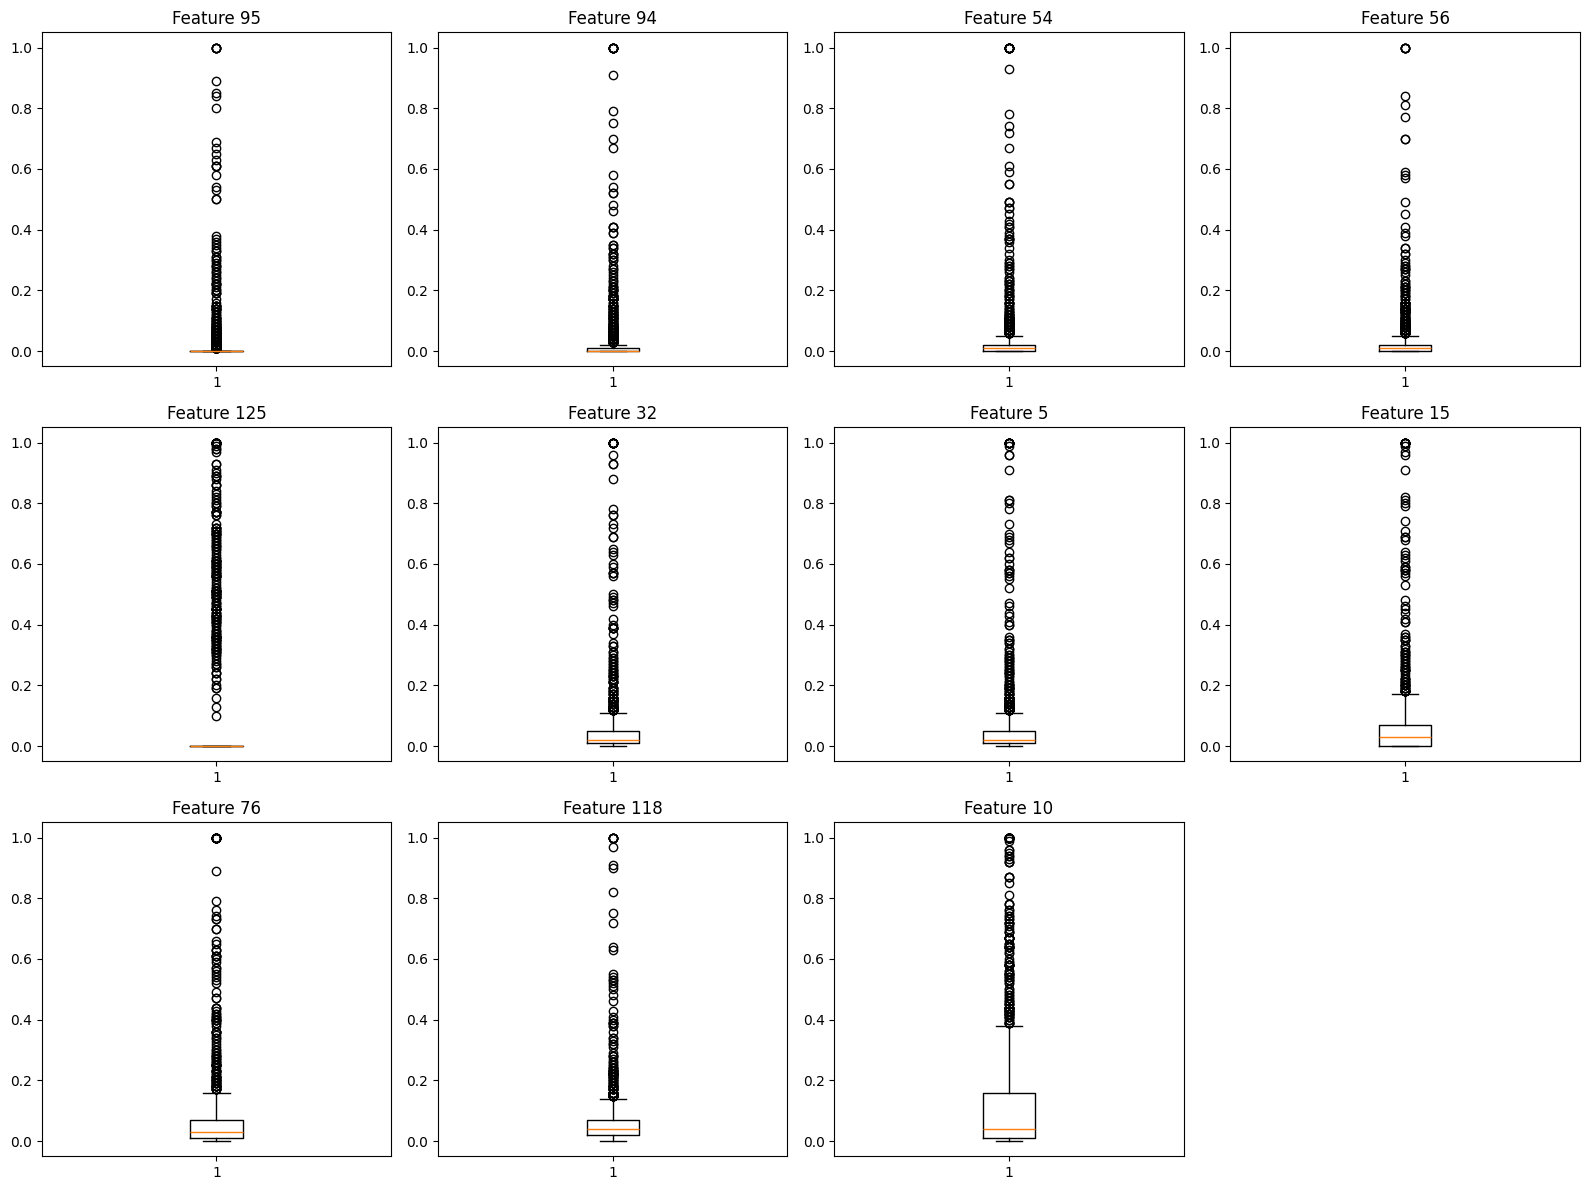

In [10]:
features = CV.nlargest(11).index

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for feature, ax in zip(features, axes.flat):
    ax.scatter(X_train[feature], y_train)
    ax.set_title(f"Feature {feature}")
    ax.set_ylabel("ViolentCrimesPerPop")

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for feature, ax in zip(features, axes.flat):
    ax.boxplot(X_train[feature])
    ax.set_title(f"Feature {feature}")

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

By just the scatter plots above, I can't make conclusions about which features are statistically significant.

### (f) Fit a linear model

In [11]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Test MSE:", mean_squared_error(y_test, y_pred))

Test MSE: 1.8099918341832492e+16


### (g) Fit a ridge regression model

In [12]:
model = RidgeCV()
model.fit(X_train, y_train)
print("Selected lambda:", model.alpha_)
print("Test MSE:", mean_squared_error(y_test, model.predict(X_test)))

Selected lambda: 1.0
Test MSE: 0.017732474992889713


### (h) Fit a LASSO model

In [13]:
for name, scaler in [
    ("Original features", "passthrough"),
    ("Standardized features", StandardScaler())
]:
    model = GridSearchCV(
        Pipeline([("scaler", scaler), ("lasso", Lasso(max_iter=10000))]),
        {"lasso__alpha": np.logspace(-4, 1, 50)}
    )
    model.fit(X_train, y_train)

    coefficients = model.best_estimator_.named_steps["lasso"].coef_

    print(name)
    print("Selected lambda:", model.best_params_["lasso__alpha"])
    print("Test MSE:", mean_squared_error(y_test, model.predict(X_test)))
    print("Selected variables:", X_train.columns[coefficients != 0].tolist())
    print()

Original features
Selected lambda: 0.00012648552168552957
Test MSE: 0.01773264258337196
Selected variables: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 57, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 104, 105, 107, 109, 111, 113, 116, 117, 118, 119, 120, 123, 124, 125, 126]

Standardized features
Selected lambda: 0.0008286427728546842
Test MSE: 0.017788640089808582
Selected variables: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 60, 64, 66, 68, 69, 72, 73, 74, 76, 77, 79, 80, 81, 82, 83, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 110, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]



Based on results above, unstandardized LASSO achieved a slightly lower test MSE (0.017733) than standardized LASSO (0.017789), so standardization did not improve test performance.

### (i) Fit a PCR model

In [14]:
model = GridSearchCV(
    Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA()),
        ("regression", LinearRegression())
    ]),
    {"pca__n_components": range(1, X_train.shape[1] + 1)},
    scoring="neg_mean_squared_error"
)
model.fit(X_train, y_train)

print("Selected M:", model.best_params_["pca__n_components"])
print("Test MSE:", mean_squared_error(y_test, model.predict(X_test)))

Selected M: 95
Test MSE: 0.018385245222066735


### (j) Fit a boosting tree

In [15]:
model = GridSearchCV(
    XGBRegressor(),
    {"reg_alpha": np.logspace(-4, 1, 50)},
    scoring="neg_mean_squared_error"
)
model.fit(X_train, y_train)

print("Selected alpha:", model.best_params_["reg_alpha"])
print("Test MSE:", mean_squared_error(y_test, model.predict(X_test)))

Selected alpha: 2.44205309454865
Test MSE: 0.017773199712335302


# AI-Use Log

Tool: Claude (Anthropic), model Claude Opus 5.5.

| ID | Exact prompt | Assignment part | How I used the response |
|---|---|---|---|
| P1 | "Without being too specific, what's a general code template to build a decision tree and plot it using skleaarn" | Question 1(b) | I used the general template to understand how to encode features, fit a `DecisionTreeClassifier`, and plot the tree with `plot_tree`. |
| P2 | "explain IF_THEN rules for a decision trees and how to convert the trees into such rules" | Question 1(c) | I learned that each root-to-leaf path is one IF-THEN rule and how to read the rules from the fitted tree (`export_text` or the `tree_` attributes). |
| P3 | "explain cost-complexity pruning and how to use it to find the minimal decision tree" | Question 1(d) | I used the explanation to understand the cost-complexity criterion, the pruning path (`cost_complexity_pruning_path`), and how to choose `ccp_alpha` by cross-validation. |
| P4 | "what is a decision rule that has high interpretability" | Question 1(d) | I used the response to understand what makes a set of rules interpretable (few, short rules with readable conditions) when writing the rules for the pruned tree. |
| P5 | "general code template to use data imputation to handle missing values" | Question 2(b) | I learned how to mark missing-value tokens when loading data and how to use `SimpleImputer`, fitting it on the training set only. |
| P6 | "how to get the correlation matrix and plot it" | Question 2(c) | I used the general code to compute the correlation matrix with `.corr()` and plot it as a heatmap. |
| P7 | "general code template to fit a PCR model with number of principal components chosen by cross validation" | Question 2(i) | I used the template to build a scaling → PCA → linear regression pipeline and choose the number of components with `GridSearchCV`. |
| P8 | "general code template to fit a boosting tree using XGBoost" | Question 2(j) | I used the template to understand how to fit an `XGBRegressor` and choose the L1 penalty `reg_alpha` by cross-validation. |